In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/navyatripathi123/02-preprocessing/__notebook__.ipynb
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/__output__.json
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/__results__.html
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/custom.css
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs/X_test.csv
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs/X_train.csv
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs/X_val.csv
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs/y_test.csv
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs/y_train.csv
/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs/y_val.csv


In [4]:
from pathlib import Path

DATA_DIR = Path("/kaggle/input/notebooks/navyatripathi123/02-preprocessing/outputs")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_val = pd.read_csv(DATA_DIR / "X_val.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_val = pd.read_csv(DATA_DIR / "y_val.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(28831, 19)
(6178, 19)
(6179, 19)
(28831,)
(6178,)
(6179,)


In [5]:
X_train.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,50,blue-collar,single,basic.4y,no,no,no,telephone,may,thu,2,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0
1,51,services,married,professional.course,unknown,no,no,telephone,may,mon,5,999,0,nonexistent,1.1,93.994,-36.4,4.858,5191.0
2,46,technician,divorced,professional.course,no,yes,no,cellular,may,mon,2,999,0,nonexistent,-1.8,92.893,-46.2,1.244,5099.1
3,46,admin.,single,university.degree,no,yes,no,telephone,jun,mon,1,999,0,nonexistent,1.4,94.465,-41.8,4.961,5228.1
4,25,services,single,high.school,no,no,no,cellular,may,thu,5,999,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1


## v1: removing features with suspiciously high information value scores.

nr.employed 1.136348

emp.var.rate 1.030894

euribor3m 1.012311

cons.conf.idx 0.834102

In [6]:
v1_drop=["nr.employed", "emp.var.rate", "euribor3m", "cons.conf.idx"]
X_train.drop(columns=v1_drop, inplace=True)
X_val.drop(columns=v1_drop, inplace=True)
X_test.drop(columns=v1_drop, inplace=True)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(28831, 15)
(6178, 15)
(6179, 15)


In [7]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
cat_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

num_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Fit on train; transform validation and test
X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

print("Train:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Test:", X_test_encoded.shape)

Train: (28831, 48)
Validation: (6178, 48)
Test: (6179, 48)


In [8]:
# separate pipeline for lr due to its need of nuemeric feature scaling
from sklearn.preprocessing import StandardScaler

num_pipeline_logistic = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline_logistic = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

preprocessor_logistic = ColumnTransformer([
    ('num', num_pipeline_logistic, num_cols),
    ('cat', cat_pipeline_logistic, cat_cols)
])

In [9]:
X_train_logistic = preprocessor_logistic.fit_transform(X_train)
X_val_logistic = preprocessor_logistic.transform(X_val)
X_test_logistic = preprocessor_logistic.transform(X_test)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

logistic = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree = DecisionTreeClassifier(
    random_state=42
)

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [12]:
models_cv = {
    "Logistic Regression": (logistic, X_train_logistic),
    "Decision Tree": (decision_tree, X_train_encoded),
    "Random Forest": (random_forest, X_train_encoded),
    "XGBoost": (xgb, X_train_encoded)
}

cv_results = []

for name, (model, X_train_model) in models_cv.items():

    scores = cross_validate(
        model,
        X_train_model,
        y_train,
        cv=cv,
        scoring=[
            "roc_auc",
            "precision",
            "recall",
            "f1"
        ],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.round(4)

,Model,CV ROC-AUC,CV Precision,CV Recall,CV F1
0,Logistic Regression,0.7611,0.6265,0.1835,0.2837
1,Decision Tree,0.6122,0.2931,0.3208,0.3062
2,Random Forest,0.7636,0.5218,0.2423,0.3303
3,XGBoost,0.7828,0.6008,0.2586,0.3614


In [13]:
logistic.fit(X_train_logistic, y_train)

decision_tree.fit(X_train_encoded, y_train)

random_forest.fit(X_train_encoded, y_train)

xgb.fit(X_train_encoded, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [14]:
logistic_prob = logistic.predict_proba(X_val_logistic)[:, 1]

dt_prob = decision_tree.predict_proba(X_val_encoded)[:, 1]

rf_prob = random_forest.predict_proba(X_val_encoded)[:, 1]

xgb_prob = xgb.predict_proba(X_val_encoded)[:, 1]

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
models = {
    "Logistic Regression": (logistic, X_val_logistic),
    "Decision Tree": (decision_tree, X_val_encoded),
    "Random Forest": (random_forest, X_val_encoded),
    "XGBoost": (xgb, X_val_encoded)
}

results = []

for name, (model, X_val_model) in models.items():

    y_pred = model.predict(X_val_model)
    y_prob = model.predict_proba(X_val_model)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

In [16]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "ROC-AUC",
    ascending=False
).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.8985,0.6202,0.2557,0.3622,0.7986
1,Random Forest,0.8940,0.5651,0.2557,0.3521,0.7720
2,Logistic Regression,0.8971,0.6786,0.1638,0.2639,0.7640
3,Decision Tree,0.8415,0.3207,0.3635,0.3407,0.6341


In [17]:
def decile_analysis(y_true, y_prob, model_name):
    
    df = pd.DataFrame({
        "actual": np.array(y_true),
        "probability": y_prob
    })
    
    # Arrange customers from highest to lowest predicted probability
    df = df.sort_values(
        "probability",
        ascending=False
    ).reset_index(drop=True)
    
    total_customers = len(df)
    overall_positive_rate = df["actual"].mean()
    
    # Divide into 20 buckets of approximately 5% each
    df["Bucket"] = pd.qcut(
        df.index,
        q=20,
        labels=False
    ) + 1
    
    results = []
    
    for bucket in range(1, 21):
        
        bucket_data = df[df["Bucket"] == bucket]
        
        customers = len(bucket_data)
        positives = bucket_data["actual"].sum()
        
        response_rate = positives / customers
        
        lift = response_rate / overall_positive_rate
        
        results.append({
            "Model": model_name,
            "Bucket": bucket,
            "Customers": customers,
            "Positive Customers": positives,
            "Response Rate": response_rate,
            "Lift": lift
        })
    
    return pd.DataFrame(results)

In [18]:
decile_logistic = decile_analysis(
    y_val,
    logistic_prob,
    "Logistic Regression"
)
decile_logistic.round(4).head()

,Model,Bucket,Customers,Positive Customers,Response Rate,Lift
0,Logistic Regression,1,309,171,0.5534,4.9122
1,Logistic Regression,2,309,123,0.3981,3.5333
2,Logistic Regression,3,309,64,0.2071,1.8385
3,Logistic Regression,4,309,36,0.1165,1.0341
4,Logistic Regression,5,309,32,0.1036,0.9192


percentage of captured customers in 
**top three buckets: 38.6%**

In [19]:
decile_dt = decile_analysis(
    y_val,
    dt_prob,
    "Decision Tree"
)
decile_dt.round(4).head()

,Model,Bucket,Customers,Positive Customers,Response Rate,Lift
0,Decision Tree,1,309,107,0.3463,3.0737
1,Decision Tree,2,309,93,0.3010,2.6715
2,Decision Tree,3,309,64,0.2071,1.8385
3,Decision Tree,4,309,22,0.0712,0.6320
4,Decision Tree,5,309,26,0.0841,0.7469


percentage of captured customers in 
**top three buckets: 28.47%**

In [20]:
decile_rf = decile_analysis(
    y_val,
    rf_prob,
    "Random Forest"
)
decile_rf.round(4).head()

,Model,Bucket,Customers,Positive Customers,Response Rate,Lift
0,Random Forest,1,309,176,0.5696,5.0558
1,Random Forest,2,309,103,0.3333,2.9588
2,Random Forest,3,309,88,0.2848,2.5279
3,Random Forest,4,309,45,0.1456,1.2927
4,Random Forest,5,309,31,0.1003,0.8905


percentage of captured customers in 
**top three buckets: 39.59%**

In [21]:
decile_xgb = decile_analysis(
    y_val,
    xgb_prob,
    "XGBoost"
)
decile_xgb.round(4).head()

,Model,Bucket,Customers,Positive Customers,Response Rate,Lift
0,XGBoost,1,309,186,0.6019,5.3431
1,XGBoost,2,309,126,0.4078,3.6195
2,XGBoost,3,309,90,0.2913,2.5854
3,XGBoost,4,309,44,0.1424,1.2640
4,XGBoost,5,309,29,0.0939,0.8331


percentage of captured customers in 
**top three buckets: 43.36%**

In [22]:
def calculate_ks(y_true, y_prob):
    
    df = pd.DataFrame({
        "actual": np.array(y_true),
        "probability": y_prob
    })
    
    # Sort from highest predicted probability to lowest
    df = df.sort_values(
        "probability",
        ascending=False
    ).reset_index(drop=True)
    
    # Total positives and negatives
    total_positives = df["actual"].sum()
    total_negatives = len(df) - total_positives
    
    # Cumulative positives and negatives
    df["cum_positives"] = df["actual"].cumsum()
    df["cum_negatives"] = (1 - df["actual"]).cumsum()
    
    # Cumulative distributions
    df["cum_positive_rate"] = (
        df["cum_positives"] / total_positives
    )
    
    df["cum_negative_rate"] = (
        df["cum_negatives"] / total_negatives
    )
    
    # KS at every customer
    df["KS"] = abs(
        df["cum_positive_rate"] -
        df["cum_negative_rate"]
    )
    
    # Maximum KS
    ks_value = df["KS"].max()
    
    # Where maximum KS occurs
    ks_index = df["KS"].idxmax()
    
    return ks_value, df, ks_index

In [23]:
ks_logistic, ks_df_logistic, ks_index_logistic = calculate_ks(
    y_val,
    logistic_prob
)

ks_dt, ks_df_dt, ks_index_dt = calculate_ks(
    y_val,
    dt_prob
)

ks_rf, ks_df_rf, ks_index_rf = calculate_ks(
    y_val,
    rf_prob
)

ks_xgb, ks_df_xgb, ks_index_xgb = calculate_ks(
    y_val,
    xgb_prob
)

In [24]:
ks_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "KS": [
        ks_logistic,
        ks_dt,
        ks_rf,
        ks_xgb
    ]
})

ks_results = ks_results.sort_values(
    "KS",
    ascending=False
).reset_index(drop=True)

ks_results.round(4)

,Model,KS
0,XGBoost,0.5038
1,Random Forest,0.4514
2,Logistic Regression,0.4206
3,Decision Tree,0.2678


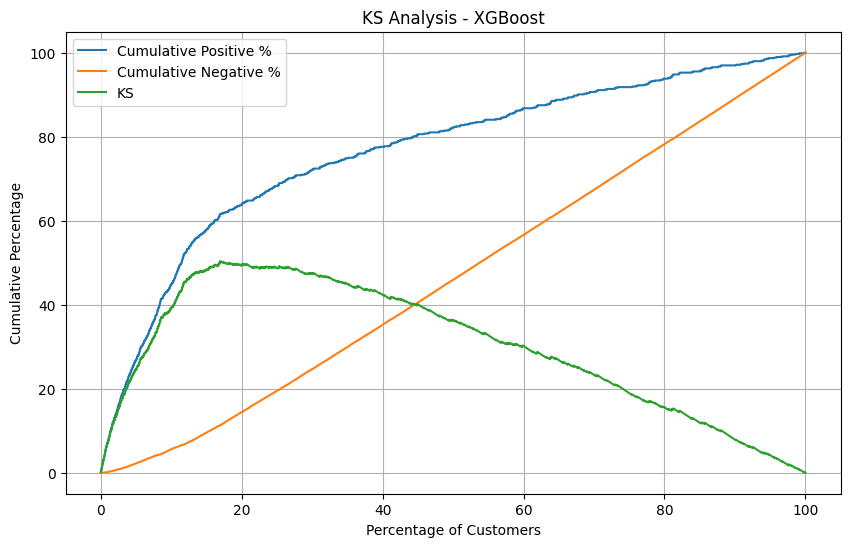

In [25]:
import matplotlib.pyplot as plt

ks_plot = ks_df_xgb.copy()

ks_plot["Customer %"] = (
    (ks_plot.index + 1) / len(ks_plot) * 100
)

plt.figure(figsize=(10, 6))

plt.plot(
    ks_plot["Customer %"],
    ks_plot["cum_positive_rate"] * 100,
    label="Cumulative Positive %"
)

plt.plot(
    ks_plot["Customer %"],
    ks_plot["cum_negative_rate"] * 100,
    label="Cumulative Negative %"
)

plt.plot(
    ks_plot["Customer %"],
    ks_plot["KS"] * 100,
    label="KS"
)

plt.xlabel("Percentage of Customers")
plt.ylabel("Cumulative Percentage")
plt.title("KS Analysis - XGBoost")
plt.legend()
plt.grid(True)

plt.show()